In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

panel = pd.read_parquet("../data/processed/weekly_demand.parquet")
panel["week"] = pd.to_datetime(panel["week"])
print(panel.shape, panel["StockCode"].nunique(),
      panel["week"].min().date(), panel["week"].max().date())

(3120, 8) 60 2010-12-06 2011-11-28


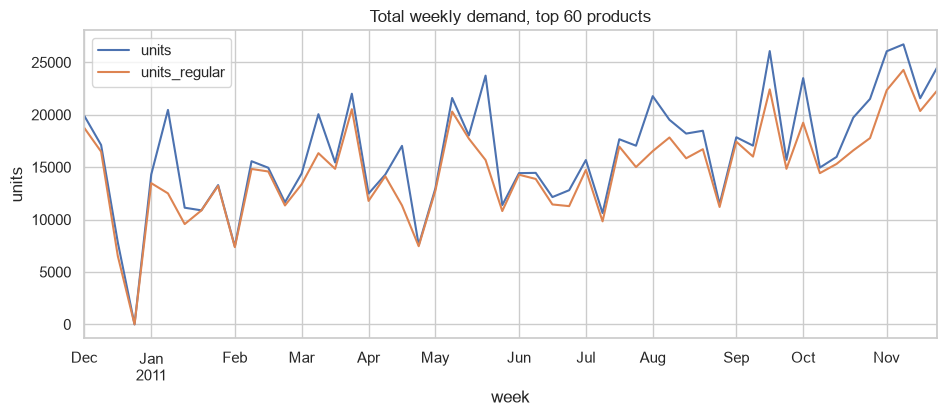

count       52.000000
mean     14716.799808
std       4457.996004
min          0.000000
25%      11690.677500
50%      14830.905000
75%      17077.125000
max      24273.670000
Name: units_regular, dtype: float64


In [2]:
total = panel.groupby("week")[["units", "units_regular"]].sum()
ax = total.plot(figsize=(11, 4), title="Total weekly demand, top 60 products")
ax.set_ylabel("units")
plt.show()
print(total["units_regular"].describe())

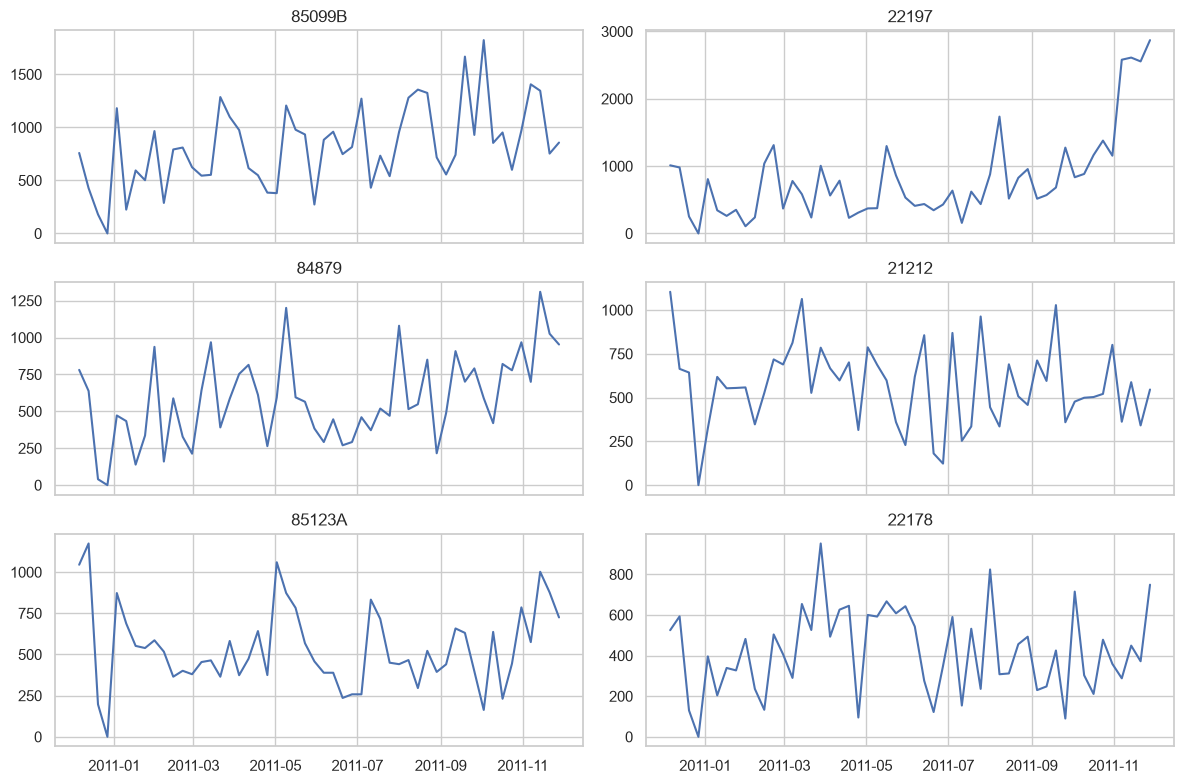

In [3]:
top6 = panel.groupby("StockCode")["units_regular"].sum().nlargest(6).index
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True)
for ax, code in zip(axes.ravel(), top6):
    s = panel[panel["StockCode"] == code].set_index("week")["units_regular"]
    ax.plot(s.index, s.values)
    ax.set_title(code)
plt.tight_layout()
plt.show()

In [5]:
g = panel.groupby("StockCode")["units_regular"]
ps = pd.DataFrame({
    "mean": g.mean(),
    "std": g.std(),
    "zero_weeks": g.apply(lambda s: (s == 0).sum()),
})
ps["cv"] = ps["std"] / ps["mean"]

late = panel[panel["week"] >= "2011-09-12"].groupby("StockCode")["units_regular"].mean()
early = panel[panel["week"] < "2011-09-12"].groupby("StockCode")["units_regular"].mean()
ps["late_vs_early"] = late / early
ps = ps.reset_index()

print(ps[["mean", "cv", "zero_weeks", "late_vs_early"]].describe())

             mean         cv  zero_weeks  late_vs_early
count   60.000000  60.000000   60.000000      60.000000
mean   245.279997   0.624780    2.083333       1.620662
std    157.001224   0.213549    2.738871       1.340431
min     33.509808   0.408540    1.000000       0.465531
25%    150.825000   0.484425    1.000000       1.063709
50%    218.075000   0.574705    1.000000       1.322935
75%    281.687500   0.679348    1.000000       1.732599
max    818.998269   1.596959   12.000000      10.312560


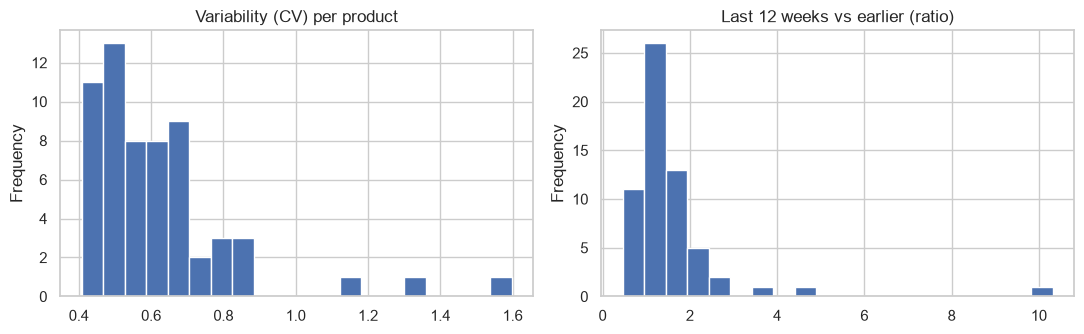

   StockCode        mean         std  zero_weeks        cv  late_vs_early
21     22086  275.384615  439.777937          10  1.596959      10.312560
23     22112  100.576923  132.078014           1  1.313204       4.630729
11     21181  210.500000  247.188068          12  1.174290       1.761858
24     22138   80.461538   70.843783           3  0.880468       3.466602
44     22722   80.480769   70.731331          11  0.878860       1.722846
   StockCode        mean         std  zero_weeks        cv  late_vs_early
21     22086  275.384615  439.777937          10  1.596959      10.312560
23     22112  100.576923  132.078014           1  1.313204       4.630729
24     22138   80.461538   70.843783           3  0.880468       3.466602
45     22726  101.000000   82.372659           5  0.815571       2.887941
27     22197  816.730769  652.709019           1  0.799173       2.587976


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ps["cv"].plot.hist(bins=20, ax=ax[0], title="Variability (CV) per product")
ps["late_vs_early"].plot.hist(bins=20, ax=ax[1], title="Last 12 weeks vs earlier (ratio)")
plt.tight_layout()
plt.show()

print(ps.sort_values("cv", ascending=False).head(5))
print(ps.sort_values("late_vs_early", ascending=False).head(5))

In [7]:
print((ps["cv"] > 1).sum(), "products with CV > 1")
print((ps["late_vs_early"] > 2).sum(), "products more than doubled in the last 12 weeks")
print((ps["zero_weeks"] >= 5).sum(), "products with 5+ zero weeks")

3 products with CV > 1
9 products more than doubled in the last 12 weeks
8 products with 5+ zero weeks


In [8]:
ps["group"] = "stable"
ps.loc[ps["zero_weeks"] >= 5, "group"] = "intermittent"
ps.loc[ps["late_vs_early"] > 2, "group"] = "seasonal_ramp"   # overrides intermittent
print(ps["group"].value_counts())

ps[["StockCode", "group"]].to_parquet("../data/processed/product_groups.parquet", index=False)

group
stable           45
seasonal_ramp     9
intermittent      6
Name: count, dtype: int64


## EDA findings
- 45 of 60 products are stable, 9 are seasonal ramps (demand more than doubled in the last 12 weeks), and 6 are intermittent (5+ zero weeks).
- Only 3 products have CV above 1 (22086, 22112, 21181); the rest are below 0.9.
- The largest ramp is 22086 (Christmas paper chain kit), at about 10x its earlier level in the last 12 weeks.
- Implication: the test period contains a seasonal peak that is not in the training history, so errors will be larger there. Results will be reported for all products and per group, using MAE and WAPE.
- Group labels are used for reporting only, not as model features, because they are computed from the test period.